<center><h1>Shelar_Kartik_HW7</h1></center>

Name: Kartik Shelar
<br>
Github Username: kartikshelar
<br>
USC ID: 4217403571

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import classification_report, calinski_harabasz_score
from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [ ]:
# Load the dataset
df = pd.read_csv("Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")

# First 22 columns are MFCC features
X = df.iloc[:, :22]

# These are the three labels for multi-label classification
y = df[["Family", "Genus", "Species"]]

# Random 70% training split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.70,
    random_state=42
)

print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Label matrix shape:", y.shape)

print("\nTraining feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

print("\nTraining label shape:", y_train.shape)
print("Test label shape:", y_test.shape)

Dataset shape: (7195, 26)
Feature matrix shape: (7195, 22)
Label matrix shape: (7195, 3)

Training feature shape: (5036, 22)
Test feature shape: (2159, 22)

Training label shape: (5036, 3)
Test label shape: (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

Every instance has three labels (Family, Genus, Species), so a classifier predicts three values per instance. With $n$ instances, $L=3$ labels, true value $y_{ij}$ and prediction $\hat y_{ij}$:

| Measure | Definition | Better |
|---|---|---|
| **Exact match ratio** (subset accuracy) | $\frac{1}{n}\sum_i \mathbb{1}[\hat y_{ij}=y_{ij}\ \text{for all}\ j]$ | higher |
| **Hamming loss** | $\frac{1}{nL}\sum_i\sum_j \mathbb{1}[\hat y_{ij}\neq y_{ij}]$ | lower |
| **Hamming score** | $1-\text{Hamming loss}$ (fraction of labels predicted correctly) | higher |

* Exact match is strict: one wrong label makes the whole instance wrong. Hamming loss and score give partial credit label by label. The *Hamming distance* of an instance is its number of wrong labels ($=L\times$ Hamming loss when averaged); it is used in Problem 2.
* Some papers define the Hamming score for set-valued labels as $|Y\cap Z|/|Y\cup Z|$ (Sorower's survey). Here every instance has exactly one value per label, so $1-$ Hamming loss is the definition used throughout.
* Example: correct Family and Genus but wrong Species gives exact match $0$, Hamming distance $1$, Hamming loss $1/3$, Hamming score $2/3$.

Training one classifier per label, as below, is the *binary relevance* approach: it treats the labels as independent.

In [ ]:
all_results = {}   # test-set measures of every model, filled in below


def evaluate_predictions(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    correct = y_true == y_pred

    exact_match = np.mean(np.all(correct, axis=1))
    hamming_loss = np.mean(~correct)
    hamming_score = 1 - hamming_loss

    print(f"Exact Match Ratio: {exact_match:.4f}")
    print(f"Hamming Loss: {hamming_loss:.4f}")
    print(f"Hamming Score: {hamming_score:.4f}")

    return {"Exact Match Ratio": exact_match,
            "Hamming Loss": hamming_loss,
            "Hamming Score": hamming_score}

#### (ii) Train a SVM for each of the labels

In [ ]:
# Wide, log-spaced ranges for the penalty C and the Gaussian kernel parameter gamma
# (footnote 1). In an earlier, narrower grid the best C sat on the edge of the grid.
param_grid = {
    "onevsrestclassifier__estimator__C": [0.1, 1, 10, 100, 1000],
    "onevsrestclassifier__estimator__gamma": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rbf_models = {}        # fitted best model for each label (standardized attributes)
rbf_params = {}        # chosen C and gamma for each label (standardized attributes)
rbf_predictions = {}   # test-set predictions for each scaling option

for scaling in ["standardized", "raw"]:
    predictions = []
    print(f"{'=' * 10} {scaling} attributes {'=' * 10}")

    for label in y_train.columns:
        steps = [StandardScaler()] if scaling == "standardized" else []
        model = make_pipeline(*steps, OneVsRestClassifier(SVC(kernel="rbf")))

        grid_search = GridSearchCV(
            model,
            param_grid=param_grid,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )

        grid_search.fit(X_train, y_train[label])

        predictions.append(grid_search.predict(X_test))
        if scaling == "standardized":
            rbf_models[label] = grid_search.best_estimator_
            rbf_params[label] = grid_search.best_params_

        best = grid_search.best_params_
        print(f"{label}: C = {best['onevsrestclassifier__estimator__C']}, "
              f"gamma = {best['onevsrestclassifier__estimator__gamma']}, "
              f"best cross-validation accuracy = {grid_search.best_score_:.4f}")

    # Arrange predictions in Family, Genus, Species order
    rbf_predictions[scaling] = np.column_stack(predictions)

    print(f"\nTest set results ({scaling} attributes):")
    all_results[f"Gaussian SVM ({scaling})"] = evaluate_predictions(y_test, rbf_predictions[scaling])
    print()

y_pred = rbf_predictions["standardized"]

========== standardized attributes ==========


Family: C = 100, gamma = 0.03, best cross-validation accuracy = 0.9917


Genus: C = 10, gamma = 0.03, best cross-validation accuracy = 0.9905


Species: C = 10, gamma = 0.03, best cross-validation accuracy = 0.9905

Test set results (standardized attributes):
Exact Match Ratio: 0.9866
Hamming Loss: 0.0097
Hamming Score: 0.9903

========== raw attributes ==========


Family: C = 10, gamma = 3, best cross-validation accuracy = 0.9929


Genus: C = 10, gamma = 3, best cross-validation accuracy = 0.9917


Species: C = 10, gamma = 3, best cross-validation accuracy = 0.9917

Test set results (raw attributes):
Exact Match Ratio: 0.9893
Hamming Loss: 0.0076
Hamming Score: 0.9924



#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [ ]:
# C from 0.001 to 1000 (log-spaced)
param_grid = {
    "linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

predictions_l1 = []
l1_models = {}

for label in y_train.columns:
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42)
    )

    grid_search = GridSearchCV(
        model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[label])

    predictions_l1.append(grid_search.predict(X_test))
    l1_models[label] = grid_search.best_estimator_

    scores = grid_search.cv_results_["mean_test_score"]
    print(f"\n{label}")
    print("Best C:", grid_search.best_params_["linearsvc__C"])
    print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")
    print("Cross-validation accuracy for C = 0.001 ... 1000:", np.round(scores, 4))

# Columns are in Family, Genus, Species order
y_pred_l1 = np.column_stack(predictions_l1)

print("\nTest set results:")
all_results["L1 SVM"] = evaluate_predictions(y_test, y_pred_l1)


Family
Best C: 10
Best cross-validation accuracy: 0.9412
Cross-validation accuracy for C = 0.001 ... 1000: [0.8529 0.9305 0.938  0.9408 0.9412 0.941  0.941 ]



Genus
Best C: 1000
Best cross-validation accuracy: 0.9517
Cross-validation accuracy for C = 0.001 ... 1000: [0.8233 0.9132 0.9422 0.9498 0.9516 0.9516 0.9517]



Species
Best C: 10
Best cross-validation accuracy: 0.9607
Cross-validation accuracy for C = 0.001 ... 1000: [0.7875 0.9162 0.9498 0.9603 0.9607 0.9605 0.9605]

Test set results:
Exact Match Ratio: 0.9125
Hamming Loss: 0.0570
Hamming Score: 0.9430


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [ ]:
param_grid = {
    "linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

predictions_smote = []
smote_models = {}

for label in y_train.columns:
    model = make_pipeline(
        StandardScaler(),
        SMOTE(random_state=42),
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=10000,
            random_state=42
        )
    )

    grid_search = GridSearchCV(
        model,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=4
    )

    grid_search.fit(X_train, y_train[label])

    predictions_smote.append(grid_search.predict(X_test))
    smote_models[label] = grid_search.best_estimator_

    print(f"\n{label}")
    print("Best C:", grid_search.best_params_["linearsvc__C"])
    print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

# Columns are in Family, Genus, Species order
y_pred_smote = np.column_stack(predictions_smote)

print("\nTest set results:")
all_results["L1 SVM + SMOTE"] = evaluate_predictions(y_test, y_pred_smote)


Family
Best C: 10
Best cross-validation accuracy: 0.9232



Genus
Best C: 1
Best cross-validation accuracy: 0.9128



Species
Best C: 10
Best cross-validation accuracy: 0.9581

Test set results:
Exact Match Ratio: 0.8536
Hamming Loss: 0.0769
Hamming Score: 0.9231


In [ ]:
for i, label in enumerate(y_test.columns):
    print(f"\n{'=' * 15} {label}: L1 SVM {'=' * 15}")
    print(classification_report(y_test[label], y_pred_l1[:, i], zero_division=0))

    print(f"\n{'=' * 15} {label}: L1 SVM + SMOTE {'=' * 15}")
    print(classification_report(y_test[label], y_pred_smote[:, i], zero_division=0))


=============== Family: L1 SVM ===============
                 precision    recall  f1-score   support

      Bufonidae       0.00      0.00      0.00        27
  Dendrobatidae       0.86      0.90      0.88       162
        Hylidae       0.89      0.90      0.90       623
Leptodactylidae       0.96      0.96      0.96      1347

       accuracy                           0.93      2159
      macro avg       0.68      0.69      0.68      2159
   weighted avg       0.92      0.93      0.92      2159


=============== Family: L1 SVM + SMOTE ===============
                 precision    recall  f1-score   support

      Bufonidae       0.36      0.89      0.51        27
  Dendrobatidae       0.73      0.98      0.84       162
        Hylidae       0.91      0.87      0.89       623
Leptodactylidae       0.97      0.92      0.94      1347

       accuracy                           0.91      2159
      macro avg       0.74      0.91      0.79      2159
   weighted avg       0.93      0.91

**Comparison of all classifiers on the test set**

In [ ]:
comparison_table = pd.DataFrame(all_results).T.round(4)
comparison_table

,Exact Match Ratio,Hamming Loss,Hamming Score
Gaussian SVM (standardized),0.9866,0.0097,0.9903
Gaussian SVM (raw),0.9893,0.0076,0.9924
L1 SVM,0.9125,0.0570,0.9430
L1 SVM + SMOTE,0.8536,0.0769,0.9231


**Conclusions for (ii)–(iv).**

* **The Gaussian-kernel SVM is clearly the best**: exact match ratio 0.987 and Hamming score 0.990 with standardized attributes (0.989 and 0.992 with raw ones). The chosen values lie inside the wide grid (standardized: $\gamma=0.03$, $C=10$–$100$; raw: $\gamma=3$, $C=10$) (for the raw attributes, $\gamma=3$ is the largest value in the grid, so I also checked $\gamma=10,30,100$ at $C=10$: the CV accuracy is lower for all three, e.g. Family 0.9869, 0.9730, 0.8062 against 0.9929), and the CV accuracy improved slightly over the narrow grid (e.g. Family 0.9905 $\to$ 0.9917). Raw and standardized attributes are nearly equivalent (the data are already normalized; the raw gain is about 6 of 2159 test instances, too small to matter), but the best $\gamma$ for raw attributes is about 100 times larger because their spread is smaller.
* **The L1-penalized linear SVM is much worse** (exact match 0.913, Hamming score 0.943); its CV accuracy is flat for $C\geq 10$. Its errors concentrate in rare classes: Bufonidae is never predicted (recall 0), and the genera Rhinella and Osteocephalus have recalls of 0.26 and 0.50.
* **SMOTE trades precision for recall and does not help overall.** Rare-class recall jumps (Bufonidae 0 $\to$ 0.89, Rhinella 0.26 $\to$ 0.93, Osteocephalus 0.50 $\to$ 0.88), but precision drops (0.36, 0.43, 0.47), accuracy falls (Family 0.93 $\to$ 0.91, Genus 0.94 $\to$ 0.90), and the Hamming score (0.943 $\to$ 0.923) and exact match ratio (0.913 $\to$ 0.854) get worse; macro F1 improves only for Family (0.68 $\to$ 0.79). It is worthwhile only if finding rare classes matters more than overall accuracy. **Overall, the Gaussian-kernel SVM without resampling is the classifier to prefer.**

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [ ]:
# Use the complete dataset from part 1
X_clustering = df.iloc[:, :22]

# Store the selected k, its score and the cluster assignments for each simulation
best_k_values = []
best_ch_scores = []
cluster_assignments = []

for simulation in range(50):
    best_score = -np.inf
    best_k = None
    best_labels = None

    for k in range(2, 51):
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=simulation)
        labels = kmeans.fit_predict(X_clustering)

        score = calinski_harabasz_score(X_clustering, labels)

        if score > best_score:
            best_score = score
            best_k = k
            best_labels = labels

    best_k_values.append(best_k)
    best_ch_scores.append(best_score)
    cluster_assignments.append(best_labels)

print("Selected k across the 50 simulations:", sorted(set(best_k_values)))
print(f"CH score of the selected solution: mean = {np.mean(best_ch_scores):.2f}, "
      f"std = {np.std(best_ch_scores):.4f}")

Selected k across the 50 simulations: [2]
CH score of the selected solution: mean = 3680.74, std = 0.0000


**Notes on 2(a).** The Calinski–Harabasz (CH) index is not defined for a single cluster, so the search runs over $k\in\{2,\dots,50\}$. CH picks $k=2$ in all 50 repetitions with exactly the same score: each repetition uses a different seed, but with 10 initializations per $k$ the best solution found is the same every time, so the Monte Carlo variation is zero and the standard deviations in 2(c) are $0$. This is a property of this data set, not an error.

### (b) Determine which family is the majority

In [ ]:
# True labels for all instances, in the same row order as X_clustering
true_labels = df[["Family", "Genus", "Species"]].reset_index(drop=True)

# Store predicted labels for all 50 simulations
all_predictions = []

for simulation in range(50):
    clusters = cluster_assignments[simulation]

    # Add cluster assignments to the true labels
    clustered_data = true_labels.copy()
    clustered_data["Cluster"] = clusters

    # Find the majority Family, Genus, and Species in each cluster
    majority_labels = clustered_data.groupby("Cluster")[
        ["Family", "Genus", "Species"]
    ].agg(lambda column: column.mode().iloc[0])

    # Assign each cluster's majority labels to its instances
    predicted_labels = majority_labels.loc[clusters].reset_index(drop=True)
    all_predictions.append(predicted_labels)

    # Display the majority labels for the first simulation
    if simulation == 0:
        print("Majority labels for each cluster in simulation 1:")
        print(majority_labels)

Majority labels for each cluster in simulation 1:
                  Family      Genus                 Species
Cluster                                                    
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1                Hylidae  Hypsiboas       HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [ ]:
results = []

for simulation, predicted_labels in enumerate(all_predictions, start=1):
    # Compare each Family, Genus, and Species prediction
    incorrect = true_labels.to_numpy() != predicted_labels.to_numpy()

    # Average number of incorrect labels per instance
    avg_hamming_distance = incorrect.sum(axis=1).mean()

    # Fraction of individual labels that are incorrect
    hamming_loss = incorrect.mean()

    # Fraction of individual labels that are correct
    hamming_score = 1 - hamming_loss

    results.append({
        "Simulation": simulation,
        "Hamming Distance": avg_hamming_distance,
        "Hamming Score": hamming_score,
        "Hamming Loss": hamming_loss
    })

results_df = pd.DataFrame(results)

print("Results for the first 5 of the 50 simulations:")
print(results_df.head().to_string(index=False))

print("\nMean and standard deviation across 50 simulations:")
print(results_df.drop(columns="Simulation").agg(["mean", "std"]).round(4))

Results for the first 5 of the 50 simulations:
 Simulation  Hamming Distance  Hamming Score  Hamming Loss
          1          0.895622       0.701459      0.298541
          2          0.895622       0.701459      0.298541
          3          0.895622       0.701459      0.298541
          4          0.895622       0.701459      0.298541
          5          0.895622       0.701459      0.298541

Mean and standard deviation across 50 simulations:
      Hamming Distance  Hamming Score  Hamming Loss
mean            0.8956         0.7015        0.2985
std             0.0000         0.0000        0.0000


**Results of 2(c).** In all 50 simulations the average Hamming distance is 0.896, the Hamming loss 0.299 and the Hamming score 0.701, with standard deviation 0. So about 0.9 of the three labels of an instance are wrong on average. The reason is clear from 2(b): with $k=2$ there are only two label triples, (Leptodactylidae, Adenomera, AdenomeraHylaedactylus) and (Hylidae, Hypsiboas, HypsiboasCordobae), so every instance of the other two families, six genera and eight species is necessarily wrong, however good the clusters are. CH is largest at $k=2$ for these data, so the requested automatic choice of $k$ is valid but a poor summary of the label structure.

## 3. ISLR 12.6.2

(a) On the basis of this dissimilarity matrix, sketch the dendrogram that results from hierarchically clustering these four observations using complete linkage. Be sure to indicate on the plot the height at which each fusion occurs, as well as the observations corresponding to each leaf in the dendrogram.

In complete linkage clustering, the dissimilarity between two clusters $A$ and $B$ is the maximum pairwise dissimilarity between an observation in $A$ and an observation in $B$:$$d_{\text{complete}}(A, B) = \max_{i \in A,\, j \in B} d(i, j)$$

1. First fusion (Height = $0.30$):

The smallest entry in the dissimilarity matrix is $d(1, 2) = 0.30$, so observations $\{1\}$ and $\{2\}$ fuse into $\{1, 2\}$ at height $0.30$.

We update the dissimilarities between $\{1, 2\}$ and the remaining observations:

$d(\{1, 2\}, \{3\}) = \max(d(1, 3),\, d(2, 3)) = \max(0.40, 0.50) = 0.50$

$d(\{1, 2\}, \{4\}) = \max(d(1, 4),\, d(2, 4)) = \max(0.70, 0.80) = 0.80$

2. Second fusion (Height = $0.45$):

Among the remaining pairs, the smallest dissimilarity is $d(3, 4) = 0.45$, so observations $\{3\}$ and $\{4\}$ fuse into $\{3, 4\}$ at height $0.45$.

3. Third fusion (Height = $0.80$):

The final two clusters $\{1, 2\}$ and $\{3, 4\}$ fuse at height:

$$d(\{1, 2\}, \{3, 4\}) = \max(d(1, 3),\, d(1, 4),\, d(2, 3),\, d(2, 4)) = \max(0.40, 0.70, 0.50, 0.80) = 0.80$$

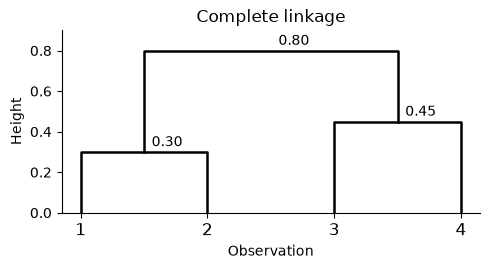

In [ ]:
import matplotlib.pyplot as plt


def draw_dendrogram(merges, leaf_order, title):
    # merges: list of (cluster_a, cluster_b, height); a cluster is a tuple of observation numbers
    x = {(obs,): pos for pos, obs in enumerate(leaf_order)}      # leaves sit at 0, 1, 2, ...
    y = {(obs,): 0.0 for obs in leaf_order}
    fig, ax = plt.subplots(figsize=(5, 2.8))
    for a, b, height in merges:
        ax.plot([x[a], x[a], x[b], x[b]], [y[a], height, height, y[b]], color="black", linewidth=1.8)
        ax.text((x[a] + x[b]) / 2 + 0.06, height + 0.012, f"{height:.2f}", ha="left", va="bottom")
        merged = tuple(sorted(a + b))
        x[merged], y[merged] = (x[a] + x[b]) / 2, height         # midway between the children
    ax.set_xticks(range(len(leaf_order)))
    ax.set_xticklabels(leaf_order, fontsize=12)
    ax.set(xlabel="Observation", ylabel="Height", title=title,
           ylim=(0, max(h for _, _, h in merges) + 0.1))
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


# Fusions for complete linkage: (cluster, cluster, height)
complete_merges = [((1,), (2,), 0.30), ((3,), (4,), 0.45), ((1, 2), (3, 4), 0.80)]

draw_dendrogram(complete_merges, [1, 2, 3, 4], "Complete linkage")

(b) Repeat (a), this time using single linkage clustering.

In single linkage clustering, the dissimilarity between two clusters $A$ and $B$ is the minimum pairwise dissimilarity between an observation in $A$ and an observation in $B$:

$$d_{\text{single}}(A, B) = \min_{i \in A,\, j \in B} d(i, j)$$

1. First fusion (Height = $0.30$):

The smallest pairwise dissimilarity is $d(1, 2) = 0.30$, so $\{1\}$ and $\{2\}$ fuse into $\{1, 2\}$ at height $0.30$. We update the dissimilarities between $\{1, 2\}$ and the remaining observations:

$d(\{1, 2\}, \{3\}) = \min(d(1, 3),\, d(2, 3)) = \min(0.40, 0.50) = 0.40$

$d(\{1, 2\}, \{4\}) = \min(d(1, 4),\, d(2, 4)) = \min(0.70, 0.80) = 0.70$

2. Second fusion (Height = $0.40$):

Comparing the remaining dissimilarities ($d(\{1, 2\}, \{3\}) = 0.40$, $d(3, 4) = 0.45$, and $d(\{1, 2\}, \{4\}) = 0.70$), the smallest is $0.40$. Thus, $\{1, 2\}$ and $\{3\}$ fuse into $\{1, 2, 3\}$ at height $0.40$.

3. Third fusion (Height = $0.45$):

The remaining clusters $\{1, 2, 3\}$ and $\{4\}$ fuse at height:$$d(\{1, 2, 3\}, \{4\}) = \min(d(1, 4),\, d(2, 4),\, d(3, 4)) = \min(0.70, 0.80, 0.45) = 0.45$$

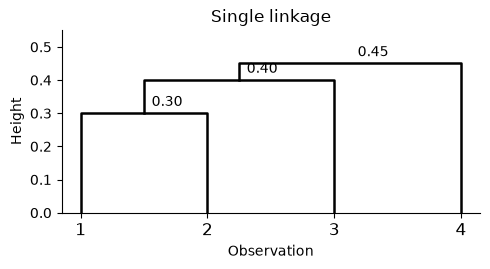

In [ ]:
# Fusions for single linkage: (cluster, cluster, height)
single_merges = [
    ((1,), (2,), 0.30),
    ((1, 2), (3,), 0.40),
    ((1, 2, 3), (4,), 0.45),
]

draw_dendrogram(single_merges, [1, 2, 3, 4], "Single linkage")

(c) Suppose that we cut the dendrogram obtained in (a) such that two clusters result. Which observations are in each cluster?

Making a horizontal cut across the dendrogram from (a) at any height between $0.45$ and $0.80$ separates the observations into two clusters: $\{1, 2\}$ and $\{3, 4\}$

(d) Suppose that we cut the dendrogram obtained in (b) such that two clusters result. Which observations are in each cluster?


Making a horizontal cut across the dendrogram from (b) at any height between $0.40$ and $0.45$ separates the observations into two clusters: $\{1, 2, 3\}$ and $\{4\}$.

(e) It is mentioned in this chapter that at each fusion in the dendrogram, the position of the two clusters being fused can be swapped without changing the meaning of the dendrogram. Draw a dendrogram that is equivalent to the dendrogram in (a), for which two or more of the leaves are repositioned, but for which the meaning of the dendrogram is the same.

Swapping the left and right branches at the top fusion (height $0.80$) places cluster $\{3, 4\}$ on the left and cluster $\{1, 2\}$ on the right. All four leaves are repositioned (3, 4, 1, 2 instead of 1, 2, 3, 4), while every fusion and height remains identical:

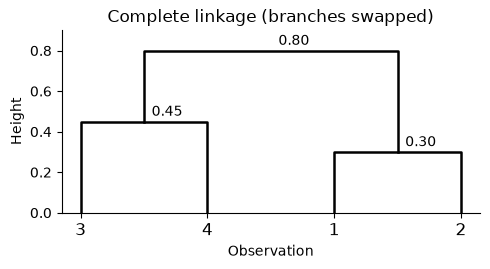

In [ ]:
# Same fusions and heights as (a); only the left/right order of the leaves changes
draw_dendrogram(complete_merges, [3, 4, 1, 2], "Complete linkage (branches swapped)")